11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 146s 89ms/step - accuracy: 0.5215 - loss: 1.5661 - val_accuracy: 0.9594 - val_loss: 0.1391
Epoch 2/8
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 130s 87ms/step - accuracy: 0.9536 - loss: 0.1690 - val_accuracy: 0.9713 - val_loss: 0.1050
Epoch 3/8
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 132s 88ms/step - accuracy: 0.9702 - loss: 0.1120 - val_accuracy: 0.9779 - val_loss: 0.0820
Epoch 4/8
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 132s 88ms/step - accuracy: 0.9529 - loss: 0.1891 - val_accuracy: 0.9797 - val_loss: 0.0717
Epoch 5/8
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 131s 87ms/step - accuracy: 0.9779 - loss: 0.0811 - val_accuracy: 0.9712 - val_loss: 0.1118
Epoch 6/8
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 131s 88ms/step - accuracy: 0.9773 - loss: 0.0821 - val_accuracy: 0.9731 - val_loss: 0.1089
Epoch 7/8
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 131s 87ms/step - accuracy: 0.9792 - loss: 0.0762 - val_accuracy: 

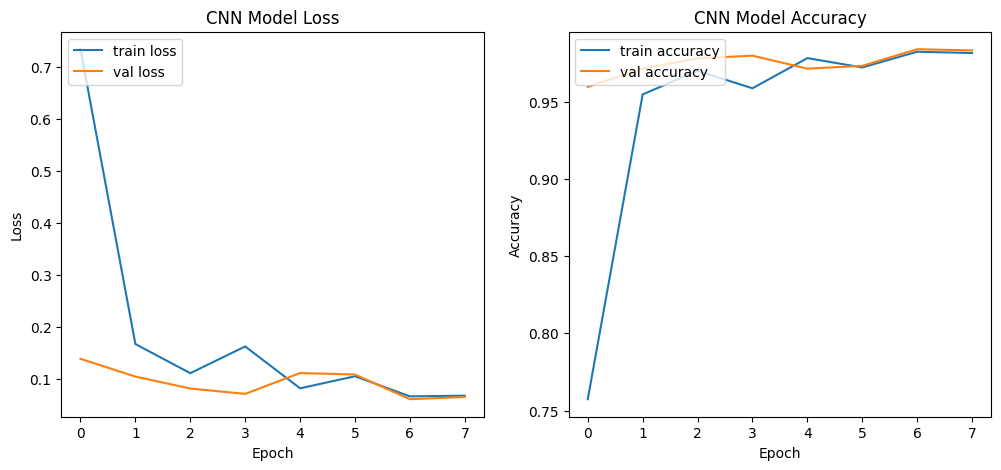

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.applications import VGG19
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import img_to_array, array_to_img
from tensorflow.keras.applications.vgg19 import preprocess_input


(train_images, train_labels), (test_images, test_labels) = mnist.load_data()


train_images = np.stack((train_images,)*3, axis=-1)
test_images = np.stack((test_images,)*3, axis=-1)


train_images_resized = np.array([img_to_array(array_to_img(img, scale=False).resize((48,48)))
                                 for img in train_images])
test_images_resized = np.array([img_to_array(array_to_img(img, scale=False).resize((48,48)))
                                for img in test_images])

train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)


base_model = VGG19(weights='imagenet', include_top=False, input_shape=(48,48,3))

model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


history = model.fit(train_images_resized, train_labels, epochs=8, validation_split=0.2)


test_loss, test_acc = model.evaluate(test_images_resized, test_labels)
print(f"Test accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss}")


fig, ax = plt.subplots(1, 2, figsize=(12, 5))


ax[0].plot(history.history['loss'], label='train loss')
ax[0].plot(history.history['val_loss'], label='val loss')
ax[0].set_title('CNN Model Loss')
ax[0].set_ylabel('Loss')
ax[0].set_xlabel('Epoch')
ax[0].legend(loc='upper left')

ax[1].plot(history.history['accuracy'], label='train accuracy')
ax[1].plot(history.history['val_accuracy'], label='val accuracy')
ax[1].set_title('CNN Model Accuracy')
ax[1].set_ylabel('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend(loc='upper left')

plt.show()
